# Barnstable and Long-Run Risk

## HBS Case

### *The Risk of Stocks in the Long-Run: The Barnstable College Endowment*

**FINM 36700 · Homework #3 · Group: 22** Lucas Albín Lazcano, Avi Rastogi, Mengting Wang, Yihan Kong

_Acknowledgements: Claude Opus 5.5 was used to set up the submission structure as well as help with coding the solutions to the problems._

# 2. Estimating Underperformance

### Data

* Monthly data covers January 1926 through December 2025.
* Stock and T-bill observations are aligned by calendar month. Both series cover all 1,200 months.

Barnstable's estimates of mean and volatility are based on the subsample of 1965 to 1999.
* We consider this subsample, as well as 2000-2025, as well as the full sample of 1926-2025.

In [72]:
import pandas as pd
import numpy as np


FILE_PATH = "barnstable_analysis_data.xlsx" 
description = pd.read_excel(FILE_PATH, sheet_name="descriptions")

returns = pd.read_excel(FILE_PATH, sheet_name="data")
description

,Unnamed: 0,Description
0,SPX,CRSP value-weighted total return for the S&P 5...
1,TB1M,"One-month Treasury yield divided by 12, expres..."


In [73]:
returns.head()

,date,SPX,TB1M
0,1926-01-30,-0.001783,0.003061
1,1926-02-27,-0.033297,0.002612
2,1926-03-31,-0.057708,0.002601
3,1926-04-30,0.038522,0.002270
4,1926-05-28,0.013623,0.002691


### Notation

* $r$ = level return rates
* $R$ = cumulative return factor
* $\texttt{r}$ = log return rates

$$ R \equiv 1+r$$

$$ \texttt{r} \equiv \ln(1+r) = \ln(R)$$

### 1. Summary Statistics

Report the following (annualized) statistics.

| | 1965-1999 | | | 2000-2025 | | | 1926-2025 | |
|---|---|---|---|---|---|---|---|---|
| | mean | vol | | mean | vol | | mean | vol |
| **levels** | $r^m$ | | | | | | | |
| | $\tilde{r}^m$ | | | | | | | |
| | $r^f$ | | | | | | | |
| **logs** | $\texttt{r}^m$ | | | | | | | |
| | $\tilde{\texttt{r}}^m$ | | | | | | | |
| | $\texttt{r}_f$ | | | | | | | |



In [74]:
returns = returns.set_index("date")           
rm, rf = returns["SPX"], returns["TB1M"]     

series = pd.DataFrame({
    "r^m":        rm,
    "r~^m":       rm - rf,
    "r^f":        rf,
    "log r^m":    np.log1p(rm),
    "log r~^m":   np.log1p(rm) - np.log1p(rf),
    "log r^f":    np.log1p(rf),
})

samples = {"1965-1999": ("1965", "1999"),
           "2000-2025": ("2000", "2025"),
           "1926-2025": ("1926", "2025")}

table = pd.concat({
    name: pd.DataFrame({"mean": series.loc[a:b].mean() * 12,
                        "vol":  series.loc[a:b].std() * np.sqrt(12)})
    for name, (a, b) in samples.items()
}, axis=1)

table.round(4)

1965-1999         2000-2025         1926-2025        
              mean     vol      mean     vol      mean     vol
r^m         0.1294  0.1494    0.0908  0.1514    0.1161  0.1860
r~^m        0.0679  0.1501    0.0726  0.1516    0.0843  0.1863
r^f         0.0615  0.0072    0.0183  0.0056    0.0318  0.0084
log r^m     0.1176  0.1496    0.0790  0.1523    0.0985  0.1853
log r~^m    0.0563  0.1503    0.0608  0.1525    0.0667  0.1855
log r^f     0.0613  0.0071    0.0182  0.0056    0.0318  0.0084

In [75]:
sharpe = pd.DataFrame({
    "levels": table.loc["r~^m"].xs("mean", level=1) / table.loc["r~^m"].xs("vol", level=1),
    "logs":   table.loc["log r~^m"].xs("mean", level=1) / table.loc["log r~^m"].xs("vol", level=1),
}).T

sharpe.round(4)

,1965-1999,2000-2025,1926-2025
levels,0.4521,0.4785,0.4523
logs,0.3746,0.3986,0.3598


* Comment on how the full-sample return stats compare to the sub-sample stats.

_Answer:_ As seen in the stats above, the raw market mean return fell from 0.1294 in 1965-1999 to 0.0908 in 2000-2025, with volatility relatively constant at around 0.15. However, if we look at excess returns, this is almost entirely due to the risk-free rate falling from 0.0615 to 0.0183, and therefore the mean excess market return is slightly higher in the 2000-2025 period than in the 1965-1999 period.

Compared to the full sample, both of the subsamples have a lower mean excess return (0.0843 for the full sample vs. 0.0679 and 0.0726 for 1965-1999 and 2000-2025, respectively). However, volatility was also higher at 0.1863 for the full sample. The Sharpe ratio of the full-sample excess return is 0.4523, essentially identical to that of 1965-1999 (0.4521) and below that of 2000-2025 (0.4785).

* Comment on how the level stats compare to the log stats.

_Answer:_ The log stats are lower than the level stats for the market across the board, but vary depending on the volatility level. The drag on the mean excess return (level stat - log stat) is 0.0116 for 1965-1999, 0.0118 for 2000-2025, and 0.0176 for the full sample. Volatilities are nearly identical between levels and logs, since ln(1+r) is approximately equal to r for small monthly returns. For the risk-free rate the difference is negligible, as its volatility is close to zero.

Because the drag scales with variance, the log transformation penalizes high-volatility periods more heavily, and the Sharpe ratio ranking changes. In levels, the full-sample Sharpe (0.4523) is essentially equal to 1965-1999 (0.4521); in logs, it is the lowest of the three (0.3598 vs. 0.3746 and 0.3986 for 1965-1999 and 2000-2025, respectively).

### 2. Probability of Underperformance

Recall the following:
- If $x\sim\mathcal{N}\left(\mu_x,\sigma_x^2\right)$, then

  $$\Pr\left[x<\ell\right] = \Phi_\mathcal{N}\left(L\right)$$

  where $L = \frac{\ell-\mu_x}{\sigma_x}$ and $\Phi_\mathcal{N}$ denotes the standard normal cdf.

- Remember that cumulative log returns are simply the sum of the single-period log returns:
  
  $$\texttt{r}^m_{t,t+h} \equiv \sum_{i=1}^h \texttt{r}^m_{t+i}$$

- It will be convenient to use and denote sample averages. We use the following notation for an $h$-period average ending at time $t+h$:
  
  $$\bar{\texttt{r}}^m_{t,t+h} = \frac{1}{h}\sum_{i=1}^h \texttt{r}^m_{t+i}$$

Calculate the probability that the cumulative market return will fall short of the cumulative risk-free return:

$$\Pr\left[R^m_{t,t+h} < R^f_{t,t+h}\right]$$

To analyze this analytically, convert the probability statement above to a probability statement about mean log returns.

_Answer:_ By the monotonicity of the logarithm and converting the statement into excess returns:
$$
R^m_{t,t+h} < R^f_{t,t+h} \iff
\sum_{i=1}^h \texttt{r}^m_{t+i} < \sum_{i=1}^h \texttt{r}^f_{t+i} \iff
\bar{\tilde{\texttt{r}}}_{t,t+h} < 0
$$

Then, if log excess returns are i.i.d. $\mathcal{N}(\mu, \sigma^2)$, we find the probability that they are below zero using the standard normal cdf.

#### 2.1 Calculate the probability using the subsample 1965-1999.



In [76]:
from scipy.stats import norm

sub = series.loc["1965":"1999", "log r~^m"]
mu, sigma = sub.mean() * 12, sub.std() * np.sqrt(12)
sharpe_ratio = mu / sigma

print(f"mu={mu:.4f}, sigma={sigma:.4f}, SR={sharpe_ratio:.4f}")

mu=0.0563, sigma=0.1503, SR=0.3746


_Answer:_ The probability that the cumulative market return will fall short of the cumulative risk-free return using the subsample 1965 to 1999 is given by the following equation, for any investment period h: 
$$
p(h) = \Phi_\mathcal{N}\left(-\sqrt{h} \times 0.375\right)
$$

#### 2.2 Report the precise probability for $h=15$ and $h=30$ years.


In [77]:
def p_under(h, SR=sharpe_ratio):
    return norm.cdf(-np.sqrt(h) * SR)

print(f"p(15)={p_under(15):.4%}, p(30)={p_under(30):.4%}")

p(15)=7.3402%, p(30)=2.0089%


_Answer:_ The probability that the cumulative market return will fall short of the cumulative risk-free return in a 15-year investment horizon and a 30-year investment horizon is 7.34% and 2.01%, respectively. We can clearly see that as the horizon increases, the probability significantly decreases.

#### 2.3 Plot the probability as a function of the investment horizon, $h$, for $0<h\le 30$ years.

**Hint**: The probability can be expressed as:

$$p(h) = \Phi_{\mathcal{N}}\left(-\sqrt{h}\;\text{SR}\right)$$

where $\text{SR}$ denotes the sample Sharpe ratio of **log** market returns.

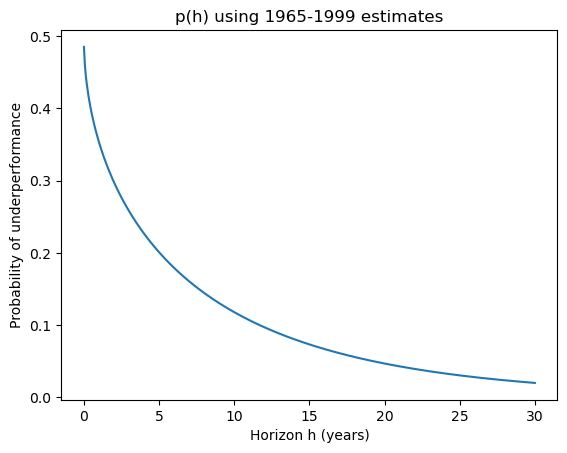

In [78]:
import matplotlib.pyplot as plt

h = np.linspace(0.01, 30, 500)

plt.plot(h, p_under(h))
plt.xlabel("Horizon h (years)")
plt.ylabel("Probability of underperformance")
plt.title("p(h) using 1965-1999 estimates")
plt.show()

_Answer:_ As seen in the graph above, the probability of underperformance falls significantly as the horizon increases, dropping from close to 50% at an extremely short horizon (0.01 years) to around 2% at a 30-year horizon. The decline is sharp in the first 10 years and then flattens afterwards. This is due to the fact that the probability depends on $\sqrt{h}$, particularly that the expected cumulative excess return grows with $h$, while its volatility only grows with $\sqrt{h}$.

### 3. Full Sample Analysis

Use the sample 1965-2025 to reconsider the 30-year probability. As of the end of 2025, calculate the probability of the stock return underperforming the risk-free rate over the next 30 years. That is, $R^m_{t,t+h}$ underperforming $R^f_{t,t+h}$ for $0<h\le 30$.

In [79]:
full = series.loc["1965":"2025", "log r~^m"]
mu_full, sigma_full = full.mean() * 12, full.std() * np.sqrt(12)
sharpe_ratio_full = mu_full / sigma_full

print(f"Probability of underperformance in the next 30 years: {p_under(30, SR=sharpe_ratio_full):.4f}")

Probability of underperformance in the next 30 years: 0.0174


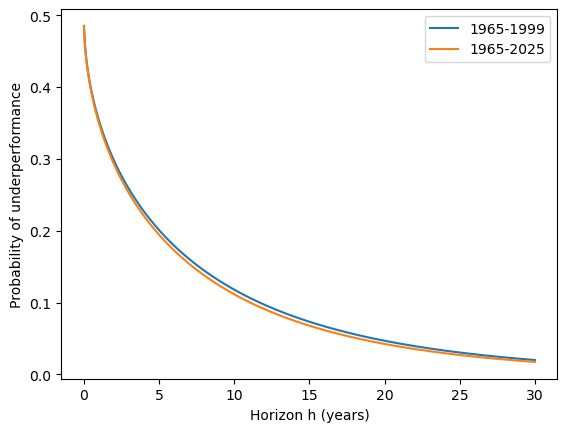

In [80]:
plt.plot(h, p_under(h), label="1965-1999")
plt.plot(h, p_under(h, SR=sharpe_ratio_full), label="1965-2025")
plt.xlabel("Horizon h (years)")
plt.ylabel("Probability of underperformance")
plt.legend()
plt.show()

_Answer:_ As seen above, the 30-year probability using the 1965-2025 sample is slightly lower than that using the 1965-1999 sample (1.74% vs. 2.01%), although both are extremely low. This is because the Sharpe ratio of log excess returns for 1965-2025 is slightly higher than for 1965-1999, as the 2000-2025 period delivered a higher log excess Sharpe ratio (0.399 vs. 0.375). A higher Sharpe ratio shifts the entire probability curve down, so the probability of underperformance falls faster with the horizon.

### 4. In-Sample Estimate of Out-of-Sample Likelihood

Let's consider how things turned out relative to Barnstable's 1999 expectations.

What was the probability (based on the 1999 estimate of $\mu$) that the `h`-year market return, $R^m_{t,t+h}$, would be smaller than that realized in `2000-2025`? 

**Hint**: You can calculate this as:

$$p = \Phi_{\mathcal{N}}\left(\sqrt{h}\; \frac{\bar{\texttt{r}}_{out-of-sample} - \bar{\texttt{r}}_{\text{in-sample}}}{\sigma_{\text{in-sample}}}\right)$$

where "in-sample" denotes 1965-1999 and "out-of-sample" denotes 2000-2025 ($h=26$ years).

In [81]:
in_s  = series.loc["1965":"1999", "log r^m"]
out_s = series.loc["2000":"2025", "log r^m"]

mu_in, sigma_in = in_s.mean() * 12, in_s.std() * np.sqrt(12)
mu_out = out_s.mean() * 12
h = 26

p = norm.cdf(np.sqrt(h) * (mu_out - mu_in) / sigma_in)
print(f"Probability: {p:.2%}")

Probability: 9.43%


_Answer:_ Based on 1999 estimates, a 26-year outcome as weak as 2000–2025 had only about a 9.43% chance. We can conclude therefore that the realized market return was a tail outcome relative to Barnstable's expectations. However, this is mainly due to the fact that we are looking at raw returns and not excess returns, and the period 2000-2025 returns were low in absolute terms relative to the previous period due to the low risk-free rate.

In [82]:
#with excess returns
in_s  = series.loc["1965":"1999", "log r~^m"]
out_s = series.loc["2000":"2025", "log r~^m"]

mu_in, sigma_in = in_s.mean() * 12, in_s.std() * np.sqrt(12)
mu_out = out_s.mean() * 12
h = 26

p = norm.cdf(np.sqrt(h) * (mu_out - mu_in) / sigma_in)
print(f"Probability: {p:.2%}")

Probability: 56.05%


_Answer:_ If we calculate the same probability using log excess returns, then we see that the realized market excess return was actually above the 1965–99's mean. Therefore we can conclude that the lower raw returns occurred due to the lower risk-free rate, not a lower equity premium.